In this notebook we will train the molecular classification model using pre-trained DreaMS. It will remain frozen - only a newly initialised classification head will be trained. We will use the training/validation splits we created in Small_data_split.ipynb.

As the validation data may have some molecules that are unknown in the training data, we remove them so that the molecules are all known from training.

In [9]:
import pandas as pd

# Load the existing datasets
train_df = pd.read_parquet(
    "model_datasets/stage_1_5pct/train.parquet"
)
validation_df = pd.read_parquet(
    "model_datasets/stage_1_5pct/validation.parquet"
)

# Identify molecules represented in training
training_molecules = set(train_df["inchikey14"].dropna().unique())

# Keep only validation spectra belonging to training molecules
validation_df_original = validation_df.copy()
validation_df = validation_df[
    validation_df["inchikey14"].isin(training_molecules)
].copy()

# Report what happened
print(f"Training spectra: {len(train_df):,}")
print(f"Original validation spectra: {len(validation_df_original):,}")
print(f"Filtered validation spectra: {len(validation_df):,}")
print(
    f"Removed unseen-molecule spectra: "
    f"{len(validation_df_original) - len(validation_df):,}"
)
print(
    f"Percentage of validation retained: "
    f"{100 * len(validation_df) / len(validation_df_original):.2f}%"
)
print(f"Unique training molecules: {len(training_molecules):,}")
print(f"Unique validation molecules retained: {validation_df['inchikey14'].nunique():,}")

Training spectra: 91,851
Original validation spectra: 22,963
Filtered validation spectra: 10,153
Removed unseen-molecule spectra: 12,810
Percentage of validation retained: 44.21%
Unique training molecules: 65,644
Unique validation molecules retained: 7,786


In [2]:
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Experiment configuration
BATCH_SIZE = 128
NUM_EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0 if os.name == "nt" else 4  # Windows: DataLoader workers can't import classes defined in a notebook

# DreaMS configuration
N_HIGHEST_PEAKS = 60

# IMPORTANT: Change this to the location of ssl_model.ckpt
DREAMS_CHECKPOINT = Path(r"D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\DreaMS_project\ssl_model.ckpt")

# Output directory
OUTPUT_DIR = Path("results/frozen_dreams_5pct")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration loaded.")

Device: cuda
GPU: NVIDIA GeForce RTX 4080
Configuration loaded.


In [3]:
required_columns = [
    "inchikey14",
    "mzs",
    "intensities",
    "precursor_mz",
    "row_id"
]

for column in required_columns:
    if column not in train_df.columns:
        raise ValueError(f"Missing column in training data: {column}")

    if column not in validation_df.columns:
        raise ValueError(f"Missing column in validation data: {column}")

print("Required columns found.")

print("Training spectra:", len(train_df))
print("Validation spectra:", len(validation_df))

print("Training molecules:", train_df["inchikey14"].nunique())
print("Validation molecules:", validation_df["inchikey14"].nunique())

Required columns found.
Training spectra: 91851
Validation spectra: 10153
Training molecules: 65644
Validation molecules: 7786


In [4]:
classes = sorted(train_df["inchikey14"].unique())

class_to_index = {
    molecule: index
    for index, molecule in enumerate(classes)
}

index_to_class = {
    index: molecule
    for molecule, index in class_to_index.items()
}

NUM_CLASSES = len(classes)

train_df = train_df.copy()
validation_df = validation_df.copy()

train_df["label"] = train_df["inchikey14"].map(class_to_index)
validation_df["label"] = validation_df["inchikey14"].map(class_to_index)

# Remove validation examples whose classes are absent from training
validation_known = validation_df["label"].notna()

validation_unknown_count = int((~validation_known).sum())

validation_known_df = validation_df.loc[validation_known].copy()

train_df["label"] = train_df["label"].astype(int)
validation_known_df["label"] = validation_known_df["label"].astype(int)

print("Number of classifier classes:", NUM_CLASSES)
print("Validation spectra with known classes:", len(validation_known_df))
print("Validation spectra with unseen classes:", validation_unknown_count)
print(
    "Validation class coverage:",
    f"{len(validation_known_df) / len(validation_df) * 100:.2f}%"
)

Number of classifier classes: 65644
Validation spectra with known classes: 10153
Validation spectra with unseen classes: 0
Validation class coverage: 100.00%


In [5]:
from dreams.api import PreTrainedModel
from dreams.models.dreams.dreams import DreaMS as DreaMSModel

from dreams.utils.data import SpectrumPreprocessor
from dreams.utils.dformats import DataFormatA

if not DREAMS_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"DreaMS checkpoint not found: {DREAMS_CHECKPOINT}"
    )

# Use DreaMS's official preprocessing implementation
dformat = DataFormatA()

spec_preprocessor = SpectrumPreprocessor(
    dformat=dformat,
    prec_intens=1.1,
    n_highest_peaks=N_HIGHEST_PEAKS,
    normalize_mzs=False,
    precision=32,
    to_relative_intensities=True
)

print("DreaMS preprocessing initialised.")

C:\Users\892hf\miniforge3\envs\dreams\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DreaMS preprocessing initialised.


In [6]:
class MoleculeSpectrumDataset(Dataset):

    def __init__(self, dataframe, preprocessor):
        self.df = dataframe.reset_index(drop=True)
        self.preprocessor = preprocessor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        mzs = np.asarray(row["mzs"], dtype=np.float32)
        intensities = np.asarray(row["intensities"], dtype=np.float32)

        if len(mzs) != len(intensities):
            raise ValueError(f"Peak-array length mismatch at row {idx}")

        if len(mzs) == 0:
            raise ValueError(f"Empty spectrum at row {idx}")

        if not np.isfinite(mzs).all() or not np.isfinite(intensities).all():
            raise ValueError(f"Non-finite peak value at row {idx}")

        if not np.isfinite(row["precursor_mz"]):
            raise ValueError(f"Invalid precursor m/z at row {idx}")

        # DreaMS expects (2, n_peaks) before preprocessing
        spectrum = np.vstack([mzs, intensities])

        # Apply official DreaMS preprocessing
        spectrum = self.preprocessor(
            spectrum,
            prec_mz=float(row["precursor_mz"]),
            high_form=False,
            augment=False
        )

        return (
            torch.tensor(spectrum, dtype=torch.float32),
            torch.tensor(int(row["label"]), dtype=torch.long)
        )


train_dataset = MoleculeSpectrumDataset(
    train_df,
    spec_preprocessor
)

validation_dataset = MoleculeSpectrumDataset(
    validation_known_df,
    spec_preprocessor
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(validation_dataset))

# Inspect one preprocessed example
example_spectrum, example_label = train_dataset[0]

print("Preprocessed spectrum shape:", example_spectrum.shape)
print("Example label:", example_label.item())

Training dataset: 91851
Validation dataset: 10153
Preprocessed spectrum shape: torch.Size([61, 2])
Example label: 14209


In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print("Data loaders created.")

Data loaders created.


In [8]:
pretrained = PreTrainedModel.from_ckpt(
    ckpt_path=str(DREAMS_CHECKPOINT),
    ckpt_cls=DreaMSModel,
    n_highest_peaks=N_HIGHEST_PEAKS
)

dreams_encoder = pretrained.model

# Freeze every pretrained parameter
for parameter in dreams_encoder.parameters():
    parameter.requires_grad = False

dreams_encoder.eval()

print("Pretrained DreaMS loaded.")
print("All transformer parameters frozen.")

Pretrained DreaMS loaded.
All transformer parameters frozen.


In [9]:
class FrozenDreaMSClassifier(nn.Module):

    def __init__(self, encoder, num_classes):
        super().__init__()

        self.encoder = encoder

        self.classifier = nn.Linear(
            1024,
            num_classes
        )

        # Ensure encoder remains frozen
        for parameter in self.encoder.parameters():
            parameter.requires_grad = False

    def train(self, mode=True):
        super().train(mode)

        # Keep the frozen encoder in evaluation mode
        self.encoder.eval()

        return self

    def forward(self, x):

        # No gradient calculation through frozen DreaMS
        with torch.no_grad():
            embeddings = self.encoder(x)

            # Use precursor-token embedding
            embeddings = embeddings[:, 0, :]

        logits = self.classifier(embeddings)

        return logits


model = FrozenDreaMSClassifier(
    encoder=dreams_encoder,
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)

FrozenDreaMSClassifier(
  (encoder): DreaMS(
    (fourier_enc): FourierFeatures()
    (ff_fourier): FeedForward(
      (ff): Sequential(
        (0): Linear(in_features=11994, out_features=512, bias=True)
        (1): Dropout(p=0.1, inplace=False)
        (2): ReLU()
        (3): Linear(in_features=512, out_features=512, bias=True)
        (4): Dropout(p=0.1, inplace=False)
        (5): ReLU()
        (6): Linear(in_features=512, out_features=512, bias=True)
        (7): Dropout(p=0.1, inplace=False)
        (8): ReLU()
        (9): Linear(in_features=512, out_features=512, bias=True)
        (10): Dropout(p=0.1, inplace=False)
        (11): ReLU()
        (12): Linear(in_features=512, out_features=980, bias=True)
        (13): ReLU()
      )
    )
    (ff_peak): FeedForward(
      (ff): Sequential(
        (0): Linear(in_features=2, out_features=44, bias=True)
        (1): ReLU()
      )
    )
    (transformer_encoder): TransformerEncoder(
      (atts): ModuleList(
        (0-6): 7 x 

In [10]:
trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

print(
    "Trainable parameters:",
    sum(p.numel() for p in trainable_parameters)
)

print(
    "Total model parameters:",
    sum(p.numel() for p in model.parameters())
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

Trainable parameters: 67285100
Total model parameters: 162834481


In [11]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0
    total = 0

    for spectra, labels in loader:

        spectra = spectra.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(spectra)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        total += labels.size(0)

    return running_loss / total


def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for spectra, labels in loader:

            spectra = spectra.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            logits = model(spectra)

            loss = criterion(logits, labels)

            predictions = torch.argmax(logits, dim=1)

            running_loss += loss.item() * labels.size(0)
            total += labels.size(0)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        running_loss / total,
        np.asarray(all_predictions),
        np.asarray(all_labels)
    )

In [12]:
history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_macro_f1": []
}

best_validation_accuracy = -1.0

best_head_path = OUTPUT_DIR / "best_classifier_head.pt"

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_predictions, val_labels = evaluate(
        model,
        validation_loader,
        criterion
    )

    val_accuracy = accuracy_score(
        val_labels,
        val_predictions
    )

    # Macro F1 over classes represented in validation.
    # Predictions into classes absent from validation remain incorrect.
    validation_classes = np.unique(val_labels)

    metric_predictions = np.where(
        np.isin(val_predictions, validation_classes),
        val_predictions,
        -1
    )

    val_macro_f1 = f1_score(
        val_labels,
        metric_predictions,
        labels=validation_classes,
        average="macro",
        zero_division=0
    )

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(val_loss)
    history["validation_accuracy"].append(val_accuracy)
    history["validation_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f}"
    )

    if val_accuracy > best_validation_accuracy:

        best_validation_accuracy = val_accuracy

        torch.save(
            model.classifier.state_dict(),
            best_head_path
        )

        print("Best classification head saved.")

print("\nTraining complete.")

Epoch 1/20 | Train loss: 13.1874 | Validation loss: 6.5020 | Accuracy: 0.2697 | Macro F1: 0.2364


Best classification head saved.


Epoch 2/20 | Train loss: 1.8288 | Validation loss: 8.3567 | Accuracy: 0.2612 | Macro F1: 0.2203


Epoch 3/20 | Train loss: 1.0017 | Validation loss: 8.3170 | Accuracy: 0.2941 | Macro F1: 0.2517


Best classification head saved.


Epoch 4/20 | Train loss: 0.6290 | Validation loss: 8.3866 | Accuracy: 0.3085 | Macro F1: 0.2643


... (17 outputs left out)

Epoch 18/20 | Train loss: 0.1414 | Validation loss: 14.7370 | Accuracy: 0.3216 | Macro F1: 0.2745


Epoch 19/20 | Train loss: 0.1314 | Validation loss: 14.9599 | Accuracy: 0.3271 | Macro F1: 0.2792


Best classification head saved.


Epoch 20/20 | Train loss: 0.1140 | Validation loss: 15.1433 | Accuracy: 0.3260 | Macro F1: 0.2785

Training complete.


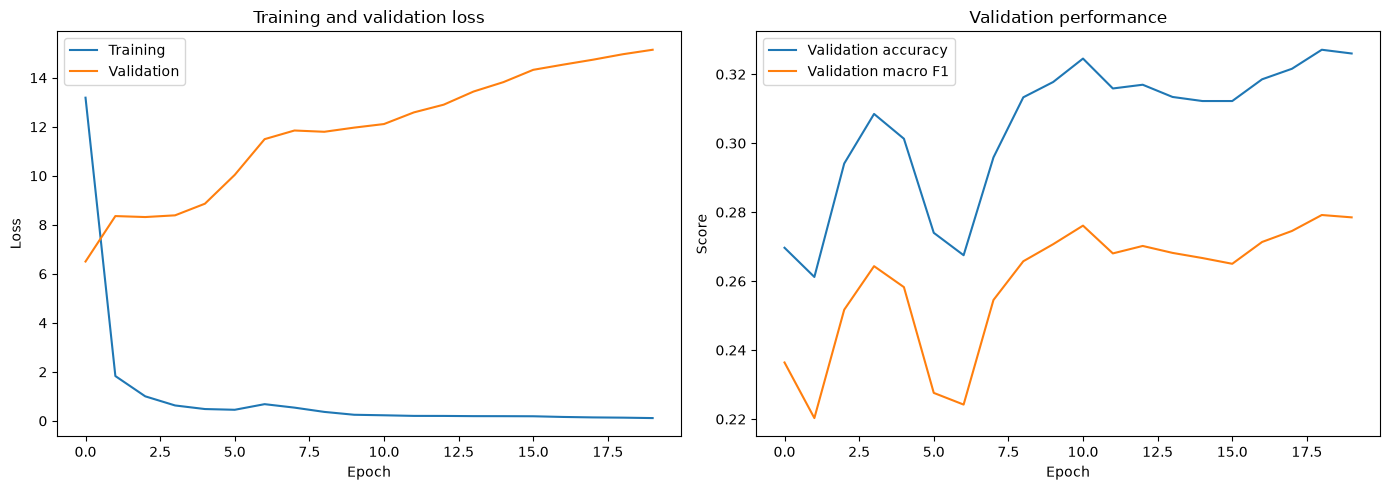

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Training")
axes[0].plot(history["validation_loss"], label="Validation")
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history["validation_accuracy"],
    label="Validation accuracy"
)
axes[1].plot(
    history["validation_macro_f1"],
    label="Validation macro F1"
)
axes[1].set_title("Validation performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
model.classifier.load_state_dict(
    torch.load(
        best_head_path,
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

val_loss, predictions, true_labels = evaluate(
    model,
    validation_loader,
    criterion
)

final_accuracy = accuracy_score(
    true_labels,
    predictions
)

final_balanced_accuracy = balanced_accuracy_score(
    true_labels,
    predictions
)

validation_classes = np.unique(true_labels)

metric_predictions = np.where(
    np.isin(predictions, validation_classes),
    predictions,
    -1
)

final_macro_f1 = f1_score(
    true_labels,
    metric_predictions,
    labels=validation_classes,
    average="macro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

print("Final frozen DreaMS validation results")
print("--------------------------------------")
print(f"Validation loss:       {val_loss:.4f}")
print(f"Accuracy:              {final_accuracy:.4f}")
print(f"Balanced accuracy:     {final_balanced_accuracy:.4f}")
print(f"Macro F1:              {final_macro_f1:.4f}")
print(f"Weighted F1:           {final_weighted_f1:.4f}")

Final frozen DreaMS validation results
--------------------------------------
Validation loss:       14.9599
Accuracy:              0.3271
Balanced accuracy:     0.2902
Macro F1:              0.2792
Weighted F1:           0.3199


C:\Users\892hf\miniforge3\envs\dreams\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [15]:
prediction_df = validation_known_df[
    ["row_id", "inchikey14"]
].copy()

prediction_df["true_label"] = true_labels
prediction_df["predicted_label"] = predictions

prediction_df["predicted_inchikey14"] = [
    index_to_class[int(label)]
    for label in predictions
]

prediction_df["correct"] = (
    prediction_df["true_label"] ==
    prediction_df["predicted_label"]
)

prediction_df.to_csv(
    OUTPUT_DIR / "validation_predictions.csv",
    index=False
)

print("Validation predictions saved.")

Validation predictions saved.


In [16]:
metrics_output = {
    "experiment": "Frozen DreaMS classification",
    "training_spectra": len(train_df),
    "validation_spectra_total": len(validation_df),
    "validation_spectra_evaluated": len(validation_known_df),
    "validation_unseen_class_spectra": validation_unknown_count,
    "number_of_training_classes": NUM_CLASSES,
    "validation_loss": float(val_loss),
    "accuracy": float(final_accuracy),
    "balanced_accuracy": float(final_balanced_accuracy),
    "macro_f1": float(final_macro_f1),
    "weighted_f1": float(final_weighted_f1),
    "best_validation_accuracy": float(best_validation_accuracy)
}

with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics_output, f, indent=4)

with open(OUTPUT_DIR / "class_mapping.json", "w") as f:
    json.dump(
        {str(k): int(v) for k, v in class_to_index.items()},
        f,
        indent=4
    )

experiment_config = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "n_highest_peaks": N_HIGHEST_PEAKS,
    "pretrained_checkpoint": str(DREAMS_CHECKPOINT),
    "frozen_encoder": True,
    "num_classes": NUM_CLASSES
}

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=4)

print("Experiment results saved.")

Experiment results saved.


In [17]:
print("Frozen DreaMS experiment finished.")
print("\nOutput files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

Frozen DreaMS experiment finished.

Output files:
best_classifier_head.pt
class_mapping.json
experiment_config.json
metrics.json
training_curves.png
validation_predictions.csv


From the results we accrued, it is clear that the training performance improved with more data, while validation went the complete opposite way. This could be strong evidence of overfitting. Let's check the training data again to see how the number of spectra per molecule really affected the result:

In [1]:
import pandas as pd

train_df = pd.read_parquet(
    "model_datasets/stage_1_5pct/train.parquet"
)

In [2]:
class_counts = train_df["inchikey14"].value_counts()

print("Training spectra per molecule:")
print(class_counts.value_counts().sort_index().head(20))

print("\nSummary:")
print(class_counts.describe())

print(
    f"\nMolecules with only 1 spectrum: "
    f"{(class_counts == 1).sum():,}"
)
print(
    f"Molecules with 2 or fewer spectra: "
    f"{(class_counts <= 2).sum():,}"
)
print(
    f"Molecules with 5 or fewer spectra: "
    f"{(class_counts <= 5).sum():,}"
)

Training spectra per molecule:
count
1     51883
2      9364
3      2179
4       854
5       437
6       264
7       170
8       115
9        84
10       46
11       43
12       29
13       28
14       19
15       22
16       23
17       14
18       11
19        3
20        8
Name: count, dtype: int64

Summary:
count    65644.000000
mean         1.399229
std          1.385178
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         59.000000
Name: count, dtype: float64

Molecules with only 1 spectrum: 51,883
Molecules with 2 or fewer spectra: 61,247
Molecules with 5 or fewer spectra: 64,717


Therefore 79% of the unique molecular classes in the training data have only 1 spectra - on average 1.4 spectra per molecule - which makes the classification extremely hard with 65,644 possible classes. We will keep this in mind when tuning the DreaMS model. 

Now we will inspect the trained head weights:

In [1]:
import torch
from pathlib import Path

HEAD_WEIGHTS_PATH = Path("best_classifier_head.pt")

assert HEAD_WEIGHTS_PATH.exists(), (
    f"Could not find weights file: {HEAD_WEIGHTS_PATH.resolve()}"
)

print(f"File: {HEAD_WEIGHTS_PATH}")
print(f"Size: {HEAD_WEIGHTS_PATH.stat().st_size / (1024**2):.2f} MB")

# Load safely where supported
try:
    head_weights = torch.load(
        HEAD_WEIGHTS_PATH,
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    # Compatibility fallback for older PyTorch versions.
    # Only use with a trusted file supplied by your GPU operator.
    head_weights = torch.load(
        HEAD_WEIGHTS_PATH,
        map_location="cpu"
    )

print("\nFile loaded successfully.")
print("Object type:", type(head_weights))

File: best_classifier_head.pt
Size: 256.67 MB

File loaded successfully.
Object type: <class 'collections.OrderedDict'>


In [2]:
if isinstance(head_weights, dict):
    print("Top-level dictionary keys:")
    for key in head_weights.keys():
        print(" -", key)

    # Identify a likely state dictionary
    if all(torch.is_tensor(v) for v in head_weights.values()):
        state_dict = head_weights
    elif "state_dict" in head_weights:
        state_dict = head_weights["state_dict"]
    elif "model_state_dict" in head_weights:
        state_dict = head_weights["model_state_dict"]
    else:
        state_dict = None

else:
    state_dict = None

if state_dict is not None:
    print("\nModel parameter tensors:")
    for name, tensor in state_dict.items():
        print(f"{name}: shape={tuple(tensor.shape)}, dtype={tensor.dtype}")
else:
    print("\nNo straightforward state dictionary identified.")

Top-level dictionary keys:
 - weight
 - bias

Model parameter tensors:
weight: shape=(65644, 1024), dtype=torch.float32
bias: shape=(65644,), dtype=torch.float32


In [3]:
if state_dict is not None:
    total_parameters = sum(
        tensor.numel()
        for tensor in state_dict.values()
    )

    print(f"Total parameters: {total_parameters:,}")

    print("\nParameter summary:")
    for name, tensor in state_dict.items():
        print(
            f"{name}: "
            f"{tensor.numel():,} parameters"
        )

Total parameters: 67,285,100

Parameter summary:
weight: 67,219,456 parameters
bias: 65,644 parameters


In [10]:
classes = sorted(train_df["inchikey14"].unique())
NUM_CLASSES = len(classes)

if state_dict is not None:
    print("\nChecking possible classifier output dimensions:")

    for name, tensor in state_dict.items():
        if tensor.ndim == 2:
            print(
                f"{name}: input dimension = {tensor.shape[1]}, "
                f"output dimension = {tensor.shape[0]}"
            )

    print("\nExpected number of classes:", NUM_CLASSES)


Checking possible classifier output dimensions:
weight: input dimension = 1024, output dimension = 65644

Expected number of classes: 65644


This confirms the weights are valid.